Trying to predict chance of 3rd down conversion

Imports

In [2]:
import pandas as pd
import nfl_data_py as nfl
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance

In [3]:
def displaystats(predictions, actual):
    cm = confusion_matrix(actual, predictions)
    print(cm)
    accuracy = accuracy_score(actual, predictions)
    print(accuracy)

In [4]:
years = [2020]
alldata = nfl.import_pbp_data(years)
print(alldata.shape)

2020 done.
Downcasting floats.
(47705, 391)


In [5]:
thirddowns = alldata[alldata["down"] == 3].copy()
print(thirddowns.shape)
exploration_df = pd.DataFrame({"Data Type": thirddowns.dtypes,"Sample Value": thirddowns.iloc[0]})
print(exploration_df.to_string())

(7439, 391)
                                     Data Type                                                                                                                         Sample Value
play_id                                float32                                                                                                                                165.0
game_id                                 object                                                                                                                       2020_01_ARI_SF
old_game_id_x                           object                                                                                                                           2020091311
home_team                               object                                                                                                                                   SF
away_team                               object                                          

In [69]:
thirddowns = thirddowns.dropna(subset=["third_down_converted"])
thirddowns["converted"] = thirddowns["third_down_converted"].astype(int)
print(thirddowns["converted"].value_counts(normalize = True))

converted
0    0.616887
1    0.383113
Name: proportion, dtype: float64


In [78]:
# features = ["yardline_100", "ydstogo", "game_seconds_remaining", "score_differential", "no_huddle", "shotgun", "posteam_timeouts_remaining", "defteam_timeouts_remaining"]
features = ["ydstogo", "half_seconds_remaining", "ydsnet"]
data = thirddowns[features + ["converted"]].dropna()
print(data.head(4))

    ydstogo  half_seconds_remaining  ydsnet  converted
6      14.0                  1659.0    41.0          0
13     20.0                  1555.0    10.0          0
20      7.0                  1423.0     3.0          0
24      5.0                  1337.0     5.0          0


In [79]:
x = data[features]
y = data["converted"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.2)

In [80]:
model = LogisticRegression()
model.fit(x_train, y_train)
predictions = model.predict(x_test)
accuracy = accuracy_score(y_test, predictions)
print(accuracy)

0.7294751009421265


In [48]:
cm = confusion_matrix(y_test, predictions)
print(cm)

[[730 174]
 [212 370]]


In [49]:
probs = model.predict_proba(x_test)[:,1]
results = x_test.copy()
results["actual"] = y_test
results["predicted prob"] = probs
print(results.head(10))

       ydstogo  ydsnet  actual  predicted prob
21567      5.0    41.0       0        0.396244
28477      9.0    63.0       0        0.461194
2194       7.0    36.0       1        0.289198
31908      5.0    59.0       0        0.566153
43113      1.0    32.0       1        0.452555
25864      7.0    69.0       0        0.589232
21399     10.0    54.0       0        0.344613
17731      3.0    50.0       0        0.552243
21265      2.0    68.0       0        0.738977
41571      8.0    75.0       1        0.609755


In [50]:
probs = model.predict_proba(x_test)[:,1]
predictions = (probs >= .6).astype(int)
cm = confusion_matrix(y_test, predictions)
print(cm)
accuracy = accuracy_score(y_test, predictions)
print(accuracy)

[[789 115]
 [290 292]]
0.7274562584118439


In [84]:
for depth in range(1, 11):   
    dtmodel = DecisionTreeClassifier(max_depth=depth, random_state=3)
    dtmodel.fit(x_train, y_train)
    predictions = dtmodel.predict(x_test)
    print(f"\n Testing depth {depth}")
    print(f"training accuracy {dtmodel.score(x_train, y_train)}")
    print(f"testing accuracy {dtmodel.score(x_test, y_test)}")
    displaystats(predictions, y_test)


 Testing depth 1
training accuracy 0.7016835016835017
testing accuracy 0.7079407806191117
[[603 302]
 [132 449]]
0.7079407806191117

 Testing depth 2
training accuracy 0.7016835016835017
testing accuracy 0.7079407806191117
[[603 302]
 [132 449]]
0.7079407806191117

 Testing depth 3
training accuracy 0.7410774410774411
testing accuracy 0.7227456258411844
[[700 205]
 [207 374]]
0.7227456258411844

 Testing depth 4
training accuracy 0.7442760942760943
testing accuracy 0.7254374158815612
[[734 171]
 [237 344]]
0.7254374158815612

 Testing depth 5
training accuracy 0.7563973063973064
testing accuracy 0.7368775235531628
[[667 238]
 [153 428]]
0.7368775235531628

 Testing depth 6
training accuracy 0.7632996632996633
testing accuracy 0.7442799461641992
[[697 208]
 [172 409]]
0.7442799461641992

 Testing depth 7
training accuracy 0.7688552188552189
testing accuracy 0.7402422611036339
[[706 199]
 [187 394]]
0.7402422611036339

 Testing depth 8
training accuracy 0.778956228956229
testing accurac

In [52]:
conversionbyyardstogo = (thirddowns.groupby("ydstogo")["converted"].mean())
print(conversionbyyardstogo.head(20))

ydstogo
1.0     0.654977
2.0     0.559578
3.0     0.519135
4.0     0.422492
5.0     0.394366
6.0     0.395765
7.0     0.347754
8.0     0.310658
9.0     0.256659
10.0    0.266768
11.0    0.273148
12.0    0.133005
13.0    0.153846
14.0    0.166667
15.0    0.166667
16.0    0.121951
17.0    0.092308
18.0    0.109589
19.0    0.050000
20.0    0.090909
Name: converted, dtype: float64


In [81]:
def viewconversionbymetric(metric):
    conversionbymetric = (thirddowns.groupby(metric)["converted"].mean())
    conversionbymetric.tail(20).plot(kind="bar", figsize = (10, 10))
    plt.title(f"Third down conversion by {metric}")
    plt.xlabel(metric)
    plt.ylabel("Conversion Rate")
    plt.show()

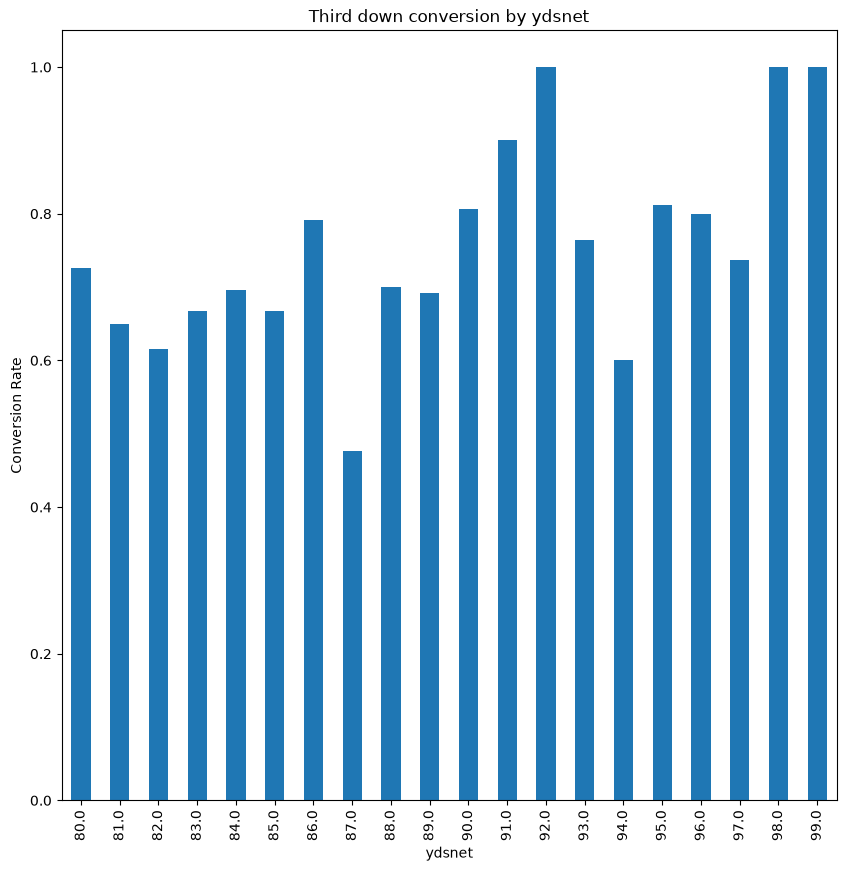

In [82]:
metric = "ydsnet"
viewconversionbymetric(metric)

                  feature  importance
2                  ydsnet    0.143338
0                 ydstogo    0.024764
1  half_seconds_remaining    0.001480


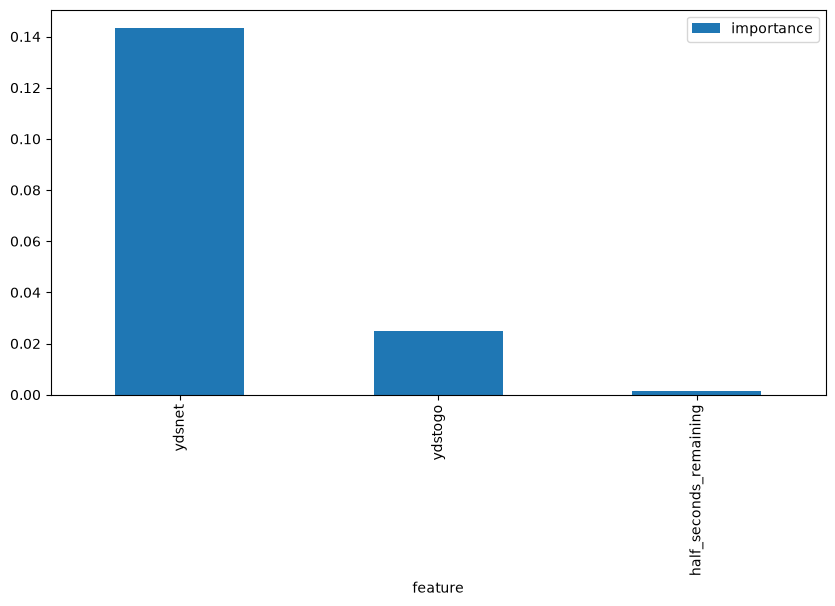

In [83]:
importance = permutation_importance(model, x_test, y_test, random_state=3)
featureimportance = pd.DataFrame({"feature": features, "importance": importance.importances_mean})
featureimportance = featureimportance.sort_values("importance", ascending=False)
print(featureimportance)
featureimportance.plot(x = "feature", y = "importance", kind = "bar", figsize = (10, 5))
plt.show()